## EDA — Malla peatonal y semaforos

Este cuaderno realiza el **Análisis Exploratorio de Datos (EDA)** de las dos capas geoespaciales base del proyecto:

1. **Malla peatonal de Bogotá D.C.** (`red_peatonal_conexion (1).gpkg`)
2. **Semaforos** (`semaforos_bogota.geojson`) 

El cuaderno está organizado así:

1. Diccionario de variables (Malla peatonal y semaforos)
2. Carga de datos
3. EDA — Malla peatonal
4. EDA — semaforos
5. Resumen y hallazgos clave

## 1. Diccionario de variables

## 1.1 Malla peatonal

| Variable | Tipo | Descripción |
|---|---|---|
| 'OBJECTID' | int | Identificador único interno del registro (ArcGIS). |
| 'CODIGO_ID' | str | Código de identificación asociado al elemento de la red peatonal. |
| 'TEMA' | str | Componente temático de la estructura territorial al que pertenece el elemento. |
| 'ELEMENTO' | str | Sistema o componente de infraestructura al que pertenece el registro. |
| 'NOMBRE' | str | Nombre o identificación del elemento físico representado por el segmento peatonal. |
| 'CLASIFICACION' | str/object | Clasificación específica del elemento dentro de la red peatonal. |
| 'ESTADO' | float | Estado o condición registrada para el elemento. En los datos observados presenta valores nulos. |
| 'ACTO_ADMINISTRATIVO' | str | Tipo o abreviatura del acto administrativo asociado al elemento. En los registros observados aparece 'DEC'. |
| 'NUMERO_ACTO_ADMINISTRATIVO' | str | Número del acto administrativo asociado al registro. En los datos observados corresponde a '555'. |
| 'FECHA_ACTO_ADMINISTRATIVO' | datetime64[ms] | Fecha correspondiente al acto administrativo asociado al elemento. |
| 'NORMATIVA' | str | Descripción de la normativa que sustenta o enmarca la información registrada. |
| 'OBSERVACION' | object | Campo destinado a registrar observaciones o información adicional sobre el elemento. |
| 'ESCALA_CAPTURA' | object | Escala utilizada para la captura o generación de la información geográfica. |
| 'FECHA_CAPTURA' | datetime64[ms] | Fecha en la que fue capturada o registrada la información geográfica. |
| 'RESPONSABLE' | str | Identificador o código asociado al responsable de la información registrada. |
| 'Shape_Length' | float64 | Longitud de la geometría lineal correspondiente al segmento de la red peatonal. |
| 'geometry' | geometry | Geometría espacial del elemento. Los registros corresponden a geometrías MULTILINESTRING que representan segmentos de la red peatonal. |


## 1.2 Semaforos

| Variable | Tipo | Descripción |
|---|---|---|
| 'OBJECTID' | int | Número único que identifica los elementos dentro de la base de datos. |
| 'ID' | int | Código numérico asignado a una intersección semaforizada específica, en una dirección única. |
| 'EXTERNO' | int | Código numérico de 4 dígitos asignado a un equipo de control que puede operar una o más intersecciones semafóricas. |
| 'DIRECCION' | str | Nomenclatura de referencia para la ubicación de una intersección semaforizada. |
| 'LOCALIDAD' | str | División político-administrativa de Bogotá D.C. a la que pertenece la intersección semaforizada. |
| 'EQUIPO' | str | Tipo de equipo de control con el cual se gestiona el funcionamiento de la intersección de referencia. |
| 'NUMEROINTERSECCIONES_POREQUIPO' | str | Cantidad de intersecciones con código ID que puede gestionar el equipo de control implementado. |
| 'UBICACIONEQUIPO' | str | Indica si el equipo de control se encuentra ubicado en la ubicación de referencia. |
| 'FECHAINSTALACION' | datetime | Fecha de entrada en operación de la intersección semaforizada. |
| 'OPERACIONACTUAL' | str | Estado de tránsito bajo el cual se encuentra funcionando la intersección semafórica. |
| 'FUNCIONAMIENTO' | str | Combinación de las diferentes estrategias de control utilizadas a nivel del controlador y de la central. |
| 'IMPLEMENTACION' | str | Estado bajo el cual se implementa la intersección semafórica. |
| 'TIPOINTERSECCION' | str | Funcionamiento de la intersección semafórica de acuerdo con el tipo o tipos de usuario que regula. |
| 'GRUPOSENALES' | int | Cantidad de entradas y salidas de una intersección semafórica que posee la dirección de referencia. |
| 'TOTALGRUPOSENALES' | int | Cantidad de entradas y salidas implementadas y operativas en el equipo de control para el externo de referencia. |
| 'NUMEROFASES' | int | Cantidad de estados de señales mediante los cuales se asigna simultáneamente el derecho de paso a uno o varios grupos vehiculares o peatonales no conflictivos. |
| 'GRUPOSVEHICULARES' | str | Nomenclatura asignada a cada paso de uso exclusivamente vehicular. |
| 'GRUPOS_BRT' | str | Nomenclatura asignada a cada paso de uso exclusivamente por bus articulado. |
| 'GRUPOSPEATONALES' | str | Nomenclatura asignada a cada paso de uso exclusivamente peatonal. |
| 'GRUPOSSONOROS' | str | Nomenclatura asignada a cada paso de uso exclusivamente para peatones en condición de discapacidad visual. |
| 'GRUPOSCICLISTAS' | str | Nomenclatura asignada a cada paso de uso exclusivamente ciclista. |
| 'CANTIDADCONTADORES' | int | Cantidad de dispositivos de conteo regresivo implementados en la intersección semafórica de referencia. |
| 'FUNCIONDETECTORES' | int | Modo de operación programado para el uso de los detectores instalados en la intersección semafórica de referencia. |
| 'ZONAAUTOMATICA' | str | Número de 4 dígitos asignado a una zona que puede contener varias intersecciones semafóricas que operan en conjunto. |
| 'geometry' | geometry | Geometría espacial que representa la ubicación de la intersección semaforizada dentro de la red. |

### **Diccionario de Variables: Columna `FUNCIONAMIENTO`**

**Definición del Dominio:** Posibles combinaciones entre las diferentes estrategias de control a nivel de controlador local y a nivel de central, que permiten gestionar de manera más eficiente las diferentes operaciones de la intersección semafórica *(Fuente: Documento Institucional GIG-06-FR-02 V.2)*.

| Código | Estrategia en Central | Estrategia en Controlador | Descripción de la Operación Semafórica | Frecuencia |
| :---: | :--- | :--- | :--- | :---: |
| **BT-TF** | Basado en Tiempo (`BT`) | Tiempos Fijos (`TF`) | Selección de planes por horario desde la central + ejecución fija preestablecida en el controlador. | 508 |
| **BT-TA** | Basado en Tiempo (`BT`) | Tráfico Actuado (`TA`) | Selección de planes por horario desde la central + optimización por algoritmo y detectores en el sitio. | 328 |
| **CA-TA** | Central Adaptativo (`CA`) | Tráfico Actuado (`TA`) | Ajuste en tiempo real de verdes/fases por detectores en central + optimización variable en el controlador. | 306 |
| **RP-TF** | Responsivo (`RP`) | Tiempos Fijos (`TF`) | Selección responsiva de planes enviada desde central según detectores + ejecución fija en el sitio. | 281 |
| **R-TF** | Responsivo (`R`) | Tiempos Fijos (`TF`) | Cambio de planes activado por demanda de tráfico + regulación constante en el controlador. | 107 |
| **R-TA** | Responsivo (`R`) | Tráfico Actuado (`TA`) | Cambio de planes activado por demanda de tráfico + ajuste por algoritmo/detectores en el sitio. | 103 |
| **RP-TA** | Responsivo (`RP`) | Tráfico Actuado (`TA`) | Selección responsiva desde central + optimización variable por detectores en el sitio. | 100 |
| **CA-TF** | Central Adaptativo (`CA`) | Tiempos Fijos (`TF`) | Control adaptativo dinámico en central + tiempos preestablecidos locales en el controlador. | 12 |

---

#### **Nomenclatura de Estrategias de Control:**

* **Control a Nivel de Central (Primeras Siglas):**
  * `BT` (**Basado en el Tiempo**): Mecanismo de selección de planes de señales activados en función de un horario o día específico.
  * `CA` (**Central Adaptativo**): Modo de control que ajusta los planes de señales basándose en las condiciones del tránsito registradas por los detectores (ajuste de tiempos de luz verde y otras acciones).
  * `RP` / `R` (**Responsivo**): Mecanismo de selección que ajusta los planes enviando órdenes de cambio a un plan determinado según las condiciones del tránsito registradas por detectores.

* **Control a Nivel de Controlador / Local (Segundas Siglas):**
  * `TA` (**Tráfico Actuado**): Control basado en programación variable accazada por un algoritmo en el controlador, optimizando la operación según las variables del tránsito detectadas en el sitio.
  * `TF` (**Tiempos Fijos**): Programación fija de planes que cambian de forma preestablecida en el controlador de manera constante y predecible, sin depender del tráfico en tiempo real.

## 1.4 **Librerias y dependencas**

In [17]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [18]:
#Datos
peatonal = gpd.read_file("Data/raw/red_peatonal_conexion (1).gpkg")
semaforos = gpd.read_file("Data/raw/semaforos_bogota.geojson")

In [19]:
print("CRS red peatonal:", peatonal.crs)
print("CRS semaforos:", semaforos.crs)

CRS red peatonal: PROJCS["PCS_CarMAGBOG",GEOGCS["GCS_CarMAGBOG",DATUM["CGS_CarMAGBOG",SPHEROID["GRS80 Mod",6380687,298.257222101]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",4.680486111],PARAMETER["central_meridian",-74.14659167],PARAMETER["scale_factor",1],PARAMETER["false_easting",92334.879],PARAMETER["false_northing",109320.965],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
CRS semaforos: EPSG:4326


### 1.5 Estandarización de CRS

Ambas capas llegan en sistemas de referencia distintos y no proyectados (`CarMAGBOG` y `EPSG:4326`), lo cual impide calcular longitudes/áreas reales en metros y complica cualquier análisis espacial conjunto (uniones, distancias, buffers). Por eso, **al inicio de este cuaderno ambas capas se reproyectan a `EPSG:3116`** (MAGNA-SIRGAS / Colombia Bogotá zone), el sistema de referencia proyectado oficial recomendado para trabajo cartográfico de precisión en Bogotá D.C., con unidades en metros.


In [20]:
# Proyectar ambas capas a EPSG:3116
peatonal = peatonal.to_crs(epsg=3116)
semaforos = semaforos.to_crs(epsg=3116)

# Verificar
print("CRS red peatona:", peatonal.crs)
print("CRS semáforos:", semaforos.crs)

CRS red peatona: EPSG:3116
CRS semáforos: EPSG:3116


## 2. EDA Malla Peatonal

## 2.1  Informacion general de los datos

In [22]:
print("Tipo de geometría:", peatonal.geom_type.unique())
peatonal.info()

Tipo de geometría: <StringArray>
['MultiLineString']
Length: 1, dtype: str
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 46065 entries, 0 to 46064
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   OBJECTID                    46065 non-null  int64         
 1   CODIGO_ID                   46065 non-null  str           
 2   TEMA                        46065 non-null  str           
 3   ELEMENTO                    46065 non-null  str           
 4   NOMBRE                      46065 non-null  str           
 5   CLASIFICACION               0 non-null      object        
 6   ESTADO                      0 non-null      float64       
 7   ACTO_ADMINISTRATIVO         46065 non-null  str           
 8   NUMERO_ACTO_ADMINISTRATIVO  46065 non-null  str           
 9   FECHA_ACTO_ADMINISTRATIVO   46065 non-null  datetime64[ms]
 10  NORMATIVA                   46065 n

## 2.2 Valores faltantes

In [23]:
nan_count = peatonal.isna().sum()

# Filtrar las columnas donde el conteo de NaN es mayor que 0
faltantes = pd.DataFrame(nan_count[nan_count > 0])

# Calcular el porcentaje de valores faltantes
faltantes["%"] = (faltantes[0] / len(peatonal)) * 100

# Imprimir el resultado
faltantes

,0,%
CLASIFICACION,46065,100.0
ESTADO,46065,100.0
OBSERVACION,46065,100.0
ESCALA_CAPTURA,46065,100.0


### Dado que en las 4 columnas tenemos el 100% de valores faltantes es informacion que no aporta al estudio se omite.
### Revisaremos ahora constantes del conjunto de datos.

In [24]:
constantes = []
for i in peatonal.columns:
    print(i, peatonal[i].nunique(dropna=False))
    if peatonal[i].nunique(dropna=False) == 1:
        constantes.append(i)

constantes


OBJECTID 46065
CODIGO_ID 46065
TEMA 1
ELEMENTO 1
NOMBRE 120
CLASIFICACION 1
ESTADO 1
ACTO_ADMINISTRATIVO 1
NUMERO_ACTO_ADMINISTRATIVO 1
FECHA_ACTO_ADMINISTRATIVO 1
NORMATIVA 1
OBSERVACION 1
ESCALA_CAPTURA 1
FECHA_CAPTURA 1
RESPONSABLE 1
Shape_Length 46043
geometry 46065


['TEMA',
 'ELEMENTO',
 'CLASIFICACION',
 'ESTADO',
 'ACTO_ADMINISTRATIVO',
 'NUMERO_ACTO_ADMINISTRATIVO',
 'FECHA_ACTO_ADMINISTRATIVO',
 'NORMATIVA',
 'OBSERVACION',
 'ESCALA_CAPTURA',
 'FECHA_CAPTURA',
 'RESPONSABLE']

Las variables no aportaban informacion para el estudio, por esta razon se omitieron.

In [ ]:
peatonal = peatonal[["OBJECTID","CODIGO_ID","NOMBRE", "Shape_Length", "geometry"]].copy()
print(peatonal.nunique()) 

OBJECTID        46065
CODIGO_ID       46065
NOMBRE            120
Shape_Length    46043
geometry        46065
dtype: int64


In [29]:
for i in peatonal.columns:
    print("**********************")
    print(peatonal[i].value_counts())
    print("*********** Nueva columna ***********")

**********************
OBJECTID
1        1
2        1
3        1
4        1
5        1
        ..
46061    1
46062    1
46063    1
46064    1
46065    1
Name: count, Length: 46065, dtype: int64
*********** Nueva columna ***********
**********************
CODIGO_ID
1        1
2        1
3        1
4        1
5        1
        ..
46061    1
46062    1
46063    1
46064    1
46065    1
Name: count, Length: 46065, dtype: int64
*********** Nueva columna ***********
**********************
NOMBRE
SIN_NMG                              26330
AVENIDA BOYACA                        1236
AVENIDA CARACAS                       1231
AVENIDA PASEO DE LOS LIBERTADORES     1061
AVENIDA CIUDAD DE QUITO                871
                                     ...  
AVENIDA EL CORTIJO                      11
AVENIDA FEDERICO LLERAS                  9
AVENIDA TIBABITA                         9
AVENIDA LA FISCALA                       6
AVENIDA CONGRESO EUCARISTICO             5
Name: count, Length: 120, dtype:

# 2.3 Verficacion de nulos en geometry o valores no concordantes

In [37]:
print("Nulos en geometry (semaforos):", peatonal.geometry.isna().sum())

Nulos en geometry (semaforos): 0


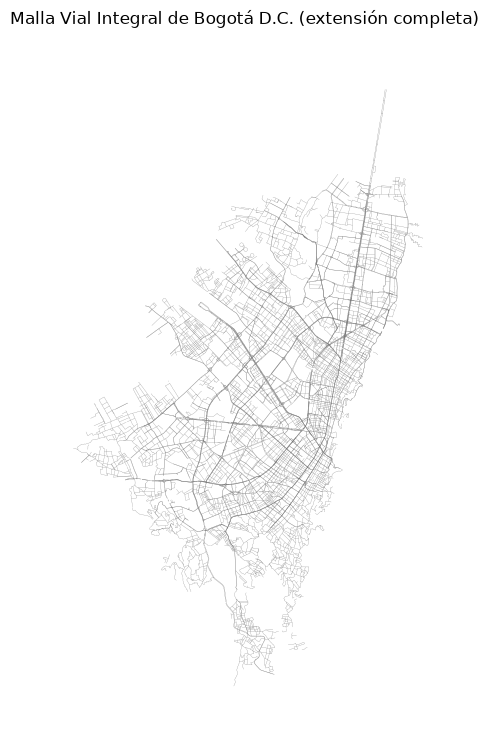

In [38]:
fig, ax = plt.subplots(figsize=(9, 9))
peatonal.plot(ax=ax, linewidth=0.15, color='dimgray')
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial Integral de Bogotá D.C. (extensión completa)')
ax.set_axis_off()
plt.show()

# 3 EDA Semaforos

In [30]:
print("Tipo de geometría:", semaforos.geom_type.unique())
semaforos.info()

Tipo de geometría: <StringArray>
['Point']
Length: 1, dtype: str
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1745 entries, 0 to 1744
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype              
---  ------                          --------------  -----              
 0   OBJECTID                        1745 non-null   int32              
 1   ID                              1745 non-null   int32              
 2   EXTERNO                         1745 non-null   int32              
 3   DIRECCION                       1745 non-null   str                
 4   LOCALIDAD                       1745 non-null   str                
 5   EQUIPO                          1745 non-null   str                
 6   NUMEROINTERSECCIONES_POREQUIPO  1745 non-null   str                
 7   UBICACIONEQUIPO                 1745 non-null   str                
 8   FECHAINSTALACION                1745 non-null   datetime64[ms, UTC]
 9   OPERACIONACT

In [31]:
nan_count = semaforos.isna().sum()

# Filtrar las columnas donde el conteo de NaN es mayor que 0
faltantes2 = pd.DataFrame(nan_count[nan_count > 0])

# Calcular el porcentaje de valores faltantes
faltantes2["%"] = (faltantes2[0] / len(semaforos)) * 100

# Imprimir el resultado
faltantes2

,0,%
GRUPOSVEHICULARES,13,0.744986
GRUPOS_BRT,2,0.114613
GRUPOSPEATONALES,13,0.744986
GRUPOSSONOROS,13,0.744986
GRUPOSCICLISTAS,8,0.458453
FUNCIONDETECTORES,8,0.458453


## El porcentaje de faltantes es menor que 1% mantenemos las variables.

In [32]:
constantes2 = []
for i in semaforos.columns:
    print(i, semaforos[i].nunique(dropna=False))
    if semaforos[i].nunique(dropna=False) == 1:
        constantes2.append(i)

constantes2

OBJECTID 1745
ID 1745
EXTERNO 1416
DIRECCION 1744
LOCALIDAD 19
EQUIPO 5
NUMEROINTERSECCIONES_POREQUIPO 5
UBICACIONEQUIPO 2
FECHAINSTALACION 1142
OPERACIONACTUAL 3
FUNCIONAMIENTO 8
IMPLEMENTACION 2
TIPOINTERSECCION 6
GRUPOSENALES 31
TOTALGRUPOSENALES 32
NUMEROFASES 6
GRUPOSVEHICULARES 742
GRUPOS_BRT 54
GRUPOSPEATONALES 822
GRUPOSSONOROS 304
GRUPOSCICLISTAS 91
CANTIDADCONTADORES 10
FUNCIONDETECTORES 83
ZONAAUTOMATICA 210
geometry 1745


[]

## No omitimos variables ni por nulos ni por entropia.

In [ ]:
for i in semaforos.columns:
    print("**********************")
    print(peatonal[i].value_counts())
    print("*********** Nueva columna ***********")

## 4. Exportar capas procesadas

Se guardan `peatonal` y `semaforos`, ya con CRS estandarizado (`EPSG:3116`) y columnas depuradas, para que otros cuadernos (por ejemplo, el de unión de las 4 bases) las importen directamente sin repetir el procesamiento.

In [ ]:
import os
os.makedirs('Data/processed', exist_ok=True)

peatonal.to_file('Data/processed/peatonal_procesada.gpkg', driver='GPKG')
semaforos.to_file('Data/processed/semaforos_procesados.gpkg', driver='GPKG')

print('Guardado: Data/processed/peatonal_procesada.gpkg', peatonal.shape)
print('Guardado: Data/processed/semaforos_procesados.gpkg', semaforos.shape)